## Importing packages

In [2]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, TimeSeriesSplit
from sklearn.feature_selection import SelectKBest, f_regression, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    classification_report,
    confusion_matrix,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    mean_absolute_error,
)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.compose import TransformedTargetRegressor

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN, SMOTETomek

from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier
from catboost import CatBoostRegressor, CatBoostClassifier
from sklearn.model_selection import KFold

import optuna
from optuna.samplers import TPESampler

import matplotlib.pyplot as plt
import joblib
from datetime import datetime

import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## Data Loading & Preparation

In [3]:
df = pd.read_csv("../data_model/db_additional_fe.csv")
df_test = pd.read_csv("../data_model/db_collected_fe.csv")

def sanitize_column_names(df):
    """Replace special JSON characters in column names with underscores."""
    import re
    sanitized = {}
    for col in df.columns:
        sanitized_col = re.sub(r'[\[\](){},\"\'\\\/\s]', '_', str(col))
        sanitized_col = re.sub(r'_+', '_', sanitized_col)
        sanitized_col = sanitized_col.strip('_')
        sanitized[col] = sanitized_col
    df = df.rename(columns=sanitized)
    return df

df = sanitize_column_names(df)
df_test = sanitize_column_names(df_test)

print(f"Data loaded: Train {df.shape}, Test {df_test.shape}")

Data loaded: Train (97927, 1556), Test (85419, 2716)


In [4]:
def align_dataframes(df1, df2, fill_value=0):
    """
    Aligns two DataFrames to have the exact same columns (union of both).
    Missing columns are added and filled with `fill_value`.
    """
    # 1. Get the union of all column names
    all_cols = df1.columns.union(df2.columns)
    
    # 2. Reindex both DataFrames to this full set of columns
    #    'fill_value' handles the new missing columns
    df1_aligned = df1.reindex(columns=all_cols, fill_value=fill_value)
    df2_aligned = df2.reindex(columns=all_cols, fill_value=fill_value)

    df1_aligned.sort_values(by='snapshot_ts', ascending=False, inplace=True)
    df2_aligned.sort_values(by='snapshot_ts', ascending=False, inplace=True)

    df1_aligned.drop_duplicates(subset='market_id', inplace=True)
    df2_aligned.drop_duplicates(subset='market_id', inplace=True)
    
    # Optional: Ensure columns are in the exact same order (reindex does this, but good to be sure)
    # The .union() usually sorts them, so they will match.
    
    return df1_aligned, df2_aligned

# --- Usage Example ---
df, df_test = align_dataframes(df, df_test, fill_value=0)

print(f"Aligned shapes: Train {df.shape}, Test {df_test.shape}")

Aligned shapes: Train (97653, 2720), Test (3905, 2720)


In [6]:
print("df:")
print(f"Median: {df['volume_total'].median()}")
print(f"Mean: {df['volume_total'].mean()}")
print(f"Std: {df['volume_total'].std()}")
print(f"Min: {df['volume_total'].min()}")
print(f"Max: {df['volume_total'].max()}")

print("df_test:")
print(f"Median: {df_test['volume_total'].median()}")
print(f"Mean: {df_test['volume_total'].mean()}")
print(f"Std: {df_test['volume_total'].std()}")
print(f"Min: {df_test['volume_total'].min()}")
print(f"Max: {df_test['volume_total'].max()}")


df:
Median: 9960.05521
Mean: 191540.51643448303
Std: 6282207.737167032
Min: 0.0101
Max: 1615812274.611232
df_test:
Median: 287.195097
Mean: 5444.097406880153
Std: 21861.00842640466
Min: 0.2
Max: 577019.850459


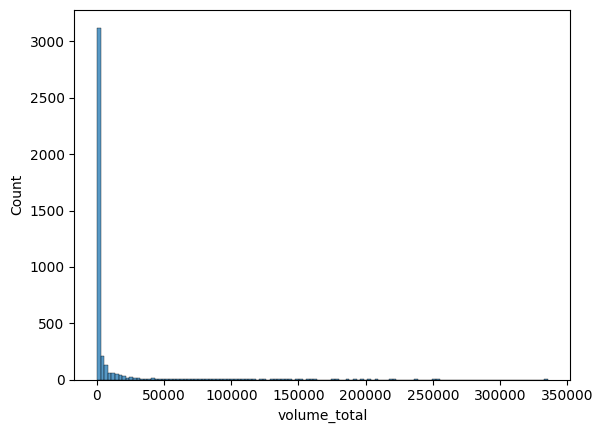

In [ ]:
sns.histplot(df_test[(df_test['volume_total'] < 500000) & (df_test['volume_total'] > 0)]['volume_total'])
plt.show()


## REGRESSION

In [6]:
# X_train_raw = df.drop(columns=['volume_total'])
# y_train_raw = df['volume_total']

# X_test_raw = df_test.drop(columns=['volume_total'])
# y_test_raw = df_test['volume_total']

# print(f"Raw data - Train: {X_train_raw.shape}, Test: {X_test_raw.shape}")
# print(f"y_train range: [{y_train_raw.min():.0f}, {y_train_raw.max():.0f}]")
# print(f"Non-zero values in y_train: {(y_train_raw > 0).sum()}")

# X_train_filled = X_train_raw.fillna(0)
# X_test_filled = X_test_raw.fillna(0)

# common_cols = X_train_filled.columns.intersection(X_test_filled.columns)
# print(f"Aligning columns: {len(X_train_filled.columns)} train, {len(X_test_filled.columns)} test → {len(common_cols)} common")
# X_train_filled = X_train_filled[common_cols]
# X_test_filled = X_test_filled[common_cols]

# X_train_filled = X_train_filled.filter(regex='emb')
# X_test_filled = X_test_filled.filter(regex='emb')

# # scaler = StandardScaler()
# # X_train_scaled = scaler.fit_transform(X_train_filled)
# # X_test_scaled = scaler.transform(X_test_filled)

# # print("\n Selecting top 150 features from", X_train_scaled.shape[1])
# # selector = SelectKBest(f_regression, k=150)
# # X_train_selected = selector.fit_transform(X_train_scaled, y_train_raw)
# # X_test_selected = selector.transform(X_test_scaled)



# # print(f" Selected features: {X_train_selected.shape[1]}")

# # selected_indices = selector.get_support(indices=True)
# # selected_features = X_train_raw.columns[selected_indices].tolist()

# print("\n Log-transforming target...")
# y_train_log = np.log1p(y_train_raw)
# y_test_log = np.log1p(y_test_raw)

# print(f"Original y_train range: [{y_train_raw.min():.0f}, {y_train_raw.max():.0f}]")
# print(f"Log-transformed y_train range: [{y_train_log.min():.2f}, {y_train_log.max():.2f}]")
# print(f"Log-transform makes scaling uniform")

In [9]:
RANDOM_STATE = 2026
N_JOBS = -1
N_TRIALS = 50
CV_FOLDS = 3  

param_spaces = {
    "xgb": {
        "n_estimators": ("int", 300, 800),   
        "max_depth": ("int", 4, 8),         
        "learning_rate": ("float", 0.01, 0.1),
        "subsample": ("float", 0.7, 1.0),
        "colsample_bytree": ("float", 0.7, 1.0),
        "min_child_weight": ("int", 1, 5),   
        "gamma": ("float", 0.1, 1.5),          
        "reg_alpha": ("float", 0.1, 2.0),    
        "reg_lambda": ("float", 0.5, 5.0),       
    },
    
    "lgbm": {
        "n_estimators": ("int", 300, 800),
        "max_depth": ("int", 5, 10),   
        "learning_rate": ("float", 0.01, 0.1),
        "num_leaves": ("int", 20, 100),   
        "subsample": ("float", 0.7, 1.0),
        "colsample_bytree": ("float", 0.7, 1.0),
        "min_child_samples": ("int", 10, 50),
        "reg_alpha": ("float", 0.1, 2.0),
        "reg_lambda": ("float", 0.5, 5.0),
    },
    
    "rf": {
        "n_estimators": ("int", 300, 800),
        "max_depth": ("int", 5, 15),        
        "min_samples_split": ("int", 5, 20),
        "min_samples_leaf": ("int", 2, 10),
        "max_features": ("categorical", ["sqrt", "log2"]),
    },
}

model_constructors = {
    "xgb": lambda params: XGBRegressor(
        objective="reg:squarederror",
        tree_method="hist",
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
        **params
    ),
    
    "lgbm": lambda params: LGBMRegressor(
        objective="regression",
        verbose=-1, 
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
        **params
    ),
    
    "rf": lambda params: RandomForestRegressor(
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
        **params
    ),
}

print(f"\n Configuration ready:")
print(f"  - N_TRIALS: {N_TRIALS}")
print(f"  - CV_FOLDS: {CV_FOLDS}")
# print(f"  - Selected features: {X_train_selected.shape[1]}")
print(f"  - Target transformed: log(1 + volume)")


 Configuration ready:
  - N_TRIALS: 50
  - CV_FOLDS: 3
  - Target transformed: log(1 + volume)


In [10]:
def get_model_type(name):
    """Extract model type from name."""
    if "xgb" in name:
        return "xgb"
    elif "lgbm" in name:
        return "lgbm"
    elif "rf" in name:
        return "rf"
    return None

# def create_regression_objective(model_name, X_train, y_train, cv):
#     """Create Optuna objective for regression."""
    
#     def objective(trial):
#         params = {}
#         for param_name, param_config in param_spaces[model_name].items():
#             param_type = param_config[0]
            
#             if param_type == "int":
#                 params[param_name] = trial.suggest_int(param_name, param_config[1], param_config[2])
#             elif param_type == "float":
#                 params[param_name] = trial.suggest_float(param_name, param_config[1], param_config[2])
#             elif param_type == "categorical":
#                 params[param_name] = trial.suggest_categorical(param_name, param_config[1])
        
#         model = model_constructors[model_name](params)
        
#         scores = cross_val_score(
#             model, X_train, y_train,
#             cv=cv,
#             scoring="neg_mean_squared_error",
#             n_jobs=N_JOBS
#         )
        
#         rmse = np.sqrt(-scores.mean())
#         return rmse
    
#     return objective

# print(" Objective functions ready")

In [9]:
# cv_regression = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# results_regression = {}

# for model_name in ["xgb", "lgbm", "rf"]:
#     print(f"\n{'='*60}")
#     print(f"Training: {model_name.upper()}")
#     print(f"{'='*60}")
    
#     study = optuna.create_study(
#         direction="minimize",
#         sampler=TPESampler(seed=RANDOM_STATE),
#         study_name=f"{model_name}_regression"
#     )
    
#     objective = create_regression_objective(model_name, X_train_filled, y_train_log, cv_regression)
    
#     print(f"Running {N_TRIALS} trials...")
#     study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    
#     best_params = study.best_params
    
#     # Train final model with best params
#     model = model_constructors[model_name](best_params)
#     model.fit(X_train_filled, y_train_log)
    
#     # Predict on test
#     y_pred_log = model.predict(X_test_filled)
#     y_pred = np.expm1(y_pred_log)  # Transform back to original scale
    
#     # Metrics on ORIGINAL scale
#     rmse = np.sqrt(mean_squared_error(y_test_raw, y_pred))
#     mae = mean_absolute_error(y_test_raw, y_pred)
#     r2 = 1 - (np.sum((y_test_raw - y_pred)**2) / np.sum((y_test_raw - y_test_raw.mean())**2))
    
#     results_regression[model_name] = {
#         "study": study,
#         "model": model,
#         "best_params": best_params,
#         "cv_rmse": study.best_value,
#         "test_rmse": rmse,
#         "test_mae": mae,
#         "test_r2": r2,
#     }
    
#     print(f"  CV RMSE (log scale): {study.best_value:.4f}")
#     print(f"  Test RMSE (original): {rmse:,.0f}")
#     print(f"  Test MAE: {mae:,.0f}")
#     print(f"  Test R²: {r2:.4f}")

In [10]:
# print(f"\n{'='*70}")
# print(f"{'='*20} REGRESSION SUMMARY {'='*20}")
# print(f"{'='*70}\n")

# print(f"{'Model':<12} {'CV RMSE':<15} {'Test RMSE':<15} {'MAE':<15} {'R²':<10}")
# print("-" * 70)

# for name, result in results_regression.items():
#     cv = result['cv_rmse']
#     test = result['test_rmse']
#     mae = result['test_mae']
#     r2 = result['test_r2']
#     print(f"{name:<12} {cv:<15.2f} {test:<15,.0f} {mae:<15,.0f} {r2:<10.4f}")

# best_reg_name = min(results_regression.items(), key=lambda x: x[1]['test_rmse'])[0]
# print(f"\n Best model by Test RMSE: {best_reg_name.upper()} (RMSE: {results_regression[best_reg_name]['test_rmse']:,.0f})")

## CLASSIFICATION

In [11]:
y_train_clf = (df['volume_total'] > 10_000).astype(int)
X_train_clf = df.drop(columns=['volume_total'])

y_test_clf = (df_test['volume_total'] > 10_000).astype(int)
X_test_clf = df_test.drop(columns=['volume_total'])

print(f"Classification data - Train: {X_train_clf.shape}, Test: {X_test_clf.shape}")
print(f"Train distribution: {(y_train_clf==0).sum()} negative ({(y_train_clf==0).sum()/len(y_train_clf):.1%}), "
      f"{(y_train_clf==1).sum()} positive ({(y_train_clf==1).sum()/len(y_train_clf):.1%})")
print(f"Test distribution: {(y_test_clf==0).sum()} negative ({(y_test_clf==0).sum()/len(y_test_clf):.1%}), "
      f"{(y_test_clf==1).sum()} positive ({(y_test_clf==1).sum()/len(y_test_clf):.1%})")


X_train_clf = X_train_clf.fillna(0)
X_test_clf = X_test_clf.fillna(0)

X_train_clf = X_train_clf.filter(regex='emb')
X_test_clf = X_test_clf.filter(regex='emb')

Classification data - Train: (97653, 2719), Test: (3905, 2719)
Train distribution: 48893 negative (50.1%), 48760 positive (49.9%)
Test distribution: 3502 negative (89.7%), 403 positive (10.3%)


In [12]:
pos_count = (y_train_clf == 1).sum()
neg_count = (y_train_clf == 0).sum()
total_count = len(y_train_clf)

current_pos_ratio = pos_count / total_count
current_neg_ratio = neg_count / total_count

target_pos_ratio = 0.05 #from test set
target_neg_ratio = 0.95 #from test set

weight_pos = target_pos_ratio / current_pos_ratio
weight_neg = target_neg_ratio / current_neg_ratio

sample_weights = np.where(y_train_clf == 1, weight_pos, weight_neg)

print(f"Train distribution: {neg_count} negative ({current_neg_ratio:.1%}), {pos_count} positive ({current_pos_ratio:.1%})")
print(f"Target distribution: 95% negative, 5% positive")
print(f"Weight for class 0 (negative): {weight_neg:.3f}")
print(f"Weight for class 1 (positive): {weight_pos:.3f}")
print(f"Sample weights shape: {sample_weights.shape}")
print(f"Sample weights ready")

Train distribution: 48893 negative (50.1%), 48760 positive (49.9%)
Target distribution: 95% negative, 5% positive
Weight for class 0 (negative): 1.897
Weight for class 1 (positive): 0.100
Sample weights shape: (97653,)
Sample weights ready


In [34]:
models_sampling = {
    "xgb_weighted": {
        "samplers": [],
        "classifier": XGBClassifier(
            objective="binary:logistic",
            tree_method="hist",
            eval_metric="aucpr",
            n_jobs=N_JOBS,
            random_state=RANDOM_STATE,
        ),
    },
    
    # "rf_weighted": {
    #     "samplers": [],
    #     "classifier": RandomForestClassifier(
    #         n_jobs=N_JOBS,
    #         random_state=RANDOM_STATE,
    #     ),
    # },
}

classifier_constructors = {
    "xgb": lambda: XGBClassifier(
        objective="binary:logistic",
        tree_method="hist",
        eval_metric="aucpr",
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
    ),
    
    "rf": lambda: RandomForestClassifier(
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
    ),
}

param_spaces_clf = {
    "xgb": {
        "n_estimators": ("int", 100, 500),
        "max_depth": ("int", 2, 6),
        "learning_rate": ("float", 0.01, 0.1),
        "subsample": ("float", 0.7, 1.0),
        "colsample_bytree": ("float", 0.7, 1.0),
        "reg_alpha": ("float", 0.1, 1.0),
        "reg_lambda": ("float", 3.0, 7.0),
        "min_child_weight": ("int", 5, 20),
        "early_stopping_rounds": ("int", 10, 50),
        "eta": ("float", 0.1, 0.5),
    },
    
    "rf": {
        "n_estimators": ("int", 100, 500),
        "max_depth": ("int", 5, 15),
        "min_samples_split": ("int", 5, 20),
        "min_samples_leaf": ("int", 2, 10),
    },
}

print("Classification models configured")

Classification models configured


In [14]:
def create_classification_objective(name, samplers, X_train, y_train, cv, sample_weights):
    """Create Optuna objective - fixed for sklearn 1.8+"""
    
    model_type = get_model_type(name)
    
    def objective(trial):
        params = {}
        for param_name, param_config in param_spaces_clf[model_type].items():
            param_type = param_config[0]
            if param_type == "int":
                params[param_name] = trial.suggest_int(param_name, param_config[1], param_config[2])
            elif param_type == "float":
                params[param_name] = trial.suggest_float(param_name, param_config[1], param_config[2])
            elif param_type == "categorical":
                params[param_name] = trial.suggest_categorical(param_name, param_config[1])

        clf = classifier_constructors[model_type]()
        clf.set_params(**params)

        scores = []
        for train_idx, valid_idx in cv.split(X_train, y_train):
            X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[valid_idx]
            y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[valid_idx]
            w_tr = sample_weights[train_idx]

            clf.fit(X_tr, y_tr, sample_weight=w_tr)
            y_pred = clf.predict_proba(X_val)[:, 1]
            scores.append(roc_auc_score(y_val, y_pred))

        return np.mean(scores)

    return objective

print("Fixed objective function ready")

Fixed objective function ready


In [15]:
cv_clf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

results_sampling = {}

for name, config in models_sampling.items():
    print(f"\n{'='*60}")
    print(f"Training: {name.upper()}")
    print(f"{'='*60}")
    
    model_type = get_model_type(name)
    
    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=RANDOM_STATE),
        study_name=f"{name}_classification"
    )
    
    objective = create_classification_objective(name, [], X_train_clf, y_train_clf, cv_clf, sample_weights)
    
    print(f"Running {N_TRIALS} trials...")
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    
    if len(study.trials) == 0 or study.best_trial is None:
        print(f"WARNING: No trials completed for {name}, skipping...")
        continue
    
    best_params = study.best_params
    
    clf = classifier_constructors[model_type]()
    clf.set_params(**best_params)
    clf.fit(X_train_clf, y_train_clf, sample_weight=sample_weights)
    
    y_pred_proba = clf.predict_proba(X_test_clf)[:, 1]
    
    precisions, recalls, thresholds = precision_recall_curve(y_test_clf, y_pred_proba)
    f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
    best_threshold_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_threshold_idx] if len(thresholds) > best_threshold_idx else 0.5
    
    y_pred = (y_pred_proba >= best_threshold).astype(int)
    
    results_sampling[name] = {
        "study": study,
        "model": clf,
        "best_params": best_params,
        "best_threshold": best_threshold,
        "cv_roc_auc": study.best_value,
        "test_recall": recall_score(y_test_clf, y_pred),
        "test_precision": precision_score(y_test_clf, y_pred, zero_division=0),
        "test_f1": f1_score(y_test_clf, y_pred),
        "test_pr_auc": average_precision_score(y_test_clf, y_pred_proba),
    }
    
    print(f"\nOptimization complete!")
    print(f"  Best CV ROC-AUC: {study.best_value:.4f}")
    print(f"  Test PR-AUC: {results_sampling[name]['test_pr_auc']:.4f}")
    print(f"  Test F1: {results_sampling[name]['test_f1']:.4f}")

[I 2026-01-29 02:40:30,745] A new study created in memory with name: xgb_weighted_classification



Training: XGB_WEIGHTED
Running 50 trials...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-01-29 02:42:46,720] Trial 0 finished with value: 0.8843504840670272 and parameters: {'n_estimators': 187, 'max_depth': 6, 'learning_rate': 0.09789719303442712, 'subsample': 0.7266697064944387, 'colsample_bytree': 0.8437869579040544, 'reg_alpha': 0.988795444813903, 'reg_lambda': 1.3916349005851316}. Best is trial 0 with value: 0.8843504840670272.
[I 2026-01-29 02:47:28,941] Trial 1 finished with value: 0.8940063382956964 and parameters: {'n_estimators': 465, 'max_depth': 6, 'learning_rate': 0.0804906521628185, 'subsample': 0.7907429768858647, 'colsample_bytree': 0.8191902980458703, 'reg_alpha': 0.36637058322138066, 'reg_lambda': 4.523398074565249}. Best is trial 1 with value: 0.8940063382956964.
[I 2026-01-29 02:48:57,194] Trial 2 finished with value: 0.8717257201078458 and parameters: {'n_estimators': 119, 'max_depth': 6, 'learning_rate': 0.060570450028216496, 'subsample': 0.8091143890796986, 'colsample_bytree': 0.9083479239847863, 'reg_alpha': 0.9310312738392569, 'reg_lambda':

[I 2026-01-29 13:47:14,449] A new study created in memory with name: rf_weighted_classification



Optimization complete!
  Best CV ROC-AUC: 0.9023
  Test PR-AUC: 0.0966
  Test F1: 0.1872

Training: RF_WEIGHTED
Running 50 trials...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-01-29 13:49:18,448] Trial 0 finished with value: 0.828787985555886 and parameters: {'n_estimators': 187, 'max_depth': 9, 'min_samples_split': 20, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.828787985555886.
[I 2026-01-29 13:53:19,049] Trial 1 finished with value: 0.8502285588516417 and parameters: {'n_estimators': 292, 'max_depth': 15, 'min_samples_split': 8, 'min_samples_leaf': 10}. Best is trial 1 with value: 0.8502285588516417.
[I 2026-01-29 13:56:50,383] Trial 2 finished with value: 0.8400113066296244 and parameters: {'n_estimators': 323, 'max_depth': 13, 'min_samples_split': 9, 'min_samples_leaf': 5}. Best is trial 1 with value: 0.8502285588516417.
[I 2026-01-29 13:59:31,162] Trial 3 finished with value: 0.8427965964069842 and parameters: {'n_estimators': 218, 'max_depth': 14, 'min_samples_split': 5, 'min_samples_leaf': 6}. Best is trial 1 with value: 0.8502285588516417.
[I 2026-01-29 14:01:52,584] Trial 4 finished with value: 0.8329715174604324 and parameters: {

In [16]:
print(f"\n{'='*80}")
print(f"{'='*20} CLASSIFICATION SUMMARY {'='*20}")
print(f"{'='*80}\n")

print(f"{'Model':<20} {'CV ROC-AUC':<12} {'Test PR-AUC':<12} {'Recall':<10} {'Precision':<12} {'F1':<10} {'Threshold':<10}")
print("-" * 110)

for name, result in results_sampling.items():
    cv_roc = result['cv_roc_auc']
    test_pr = result['test_pr_auc']
    recall = result['test_recall']
    precision = result['test_precision']
    f1 = result['test_f1']
    threshold = result['best_threshold']
    
    print(f"{name:<20} {cv_roc:<12.4f} {test_pr:<12.4f} {recall:<10.4f} {precision:<12.4f} {f1:<10.4f} {threshold:<10.3f}")

best_pr_auc_name = max(results_sampling.items(), key=lambda x: x[1]['test_pr_auc'])[0]
print(f"\n Best model by PR-AUC: {best_pr_auc_name.upper()} (PR-AUC: {results_sampling[best_pr_auc_name]['test_pr_auc']:.4f})")

best_f1_name = max(results_sampling.items(), key=lambda x: x[1]['test_f1'])[0]
print(f" Best model by F1: {best_f1_name.upper()} (F1: {results_sampling[best_f1_name]['test_f1']:.4f})")


==================== CLASSIFICATION SUMMARY ====================

Model                CV ROC-AUC   Test PR-AUC  Recall     Precision    F1         Threshold 
--------------------------------------------------------------------------------------------------------------
xgb_weighted         0.9023       0.0966       1.0000     0.1033       0.1872     0.000     
rf_weighted          0.8508       0.0961       1.0000     0.1037       0.1878     0.046     

 Best model by PR-AUC: XGB_WEIGHTED (PR-AUC: 0.0966)
 Best model by F1: RF_WEIGHTED (F1: 0.1878)


## Save Best Models

In [17]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# # Save best regression model
# best_reg_name = min(results_regression.items(), key=lambda x: x[1]['test_rmse'])[0]
# best_reg_model = results_regression[best_reg_name]["model"]

# reg_filename = f"best_regressor_{best_reg_name}_{timestamp}.pkl"
# joblib.dump(best_reg_model, reg_filename)
# print(f"✅ Best regression model saved: {reg_filename}")

# Save best classification model
best_clf_name = max(results_sampling.items(), key=lambda x: x[1]['test_pr_auc'])[0]
best_clf_pipe = results_sampling[best_clf_name]["best_pipe"]

clf_filename = f"best_classifier_{best_clf_name}_{timestamp}.pkl"
joblib.dump(best_clf_pipe, clf_filename)
print(f"✅ Best classifier saved: {clf_filename}")

print(f"\n{'='*60}")
print(f"TRAINING COMPLETE!")
print(f"{'='*60}")

KeyError: 'best_pipe'

In [24]:
# === Train final XGBoost model with best Optuna parameters and submit to W&B ===

import wandb
from wandb.integration.xgboost import WandbCallback
import numpy as np
import xgboost as xgb
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
)

RANDOM_STATE = 2026

# 1. Extract best XGB study and its parameters from results_sampling
best_xgb_study = results_sampling["xgb_weighted"]["study"]
best_xgb_params = best_xgb_study.best_params

print("Best XGBoost params from Optuna:")
for k, v in best_xgb_params.items():
    print(f"  {k}: {v}")

# 2. Prepare DMatrices
dtrain = xgb.DMatrix(X_train_clf, label=y_train_clf, weight=sample_weights)
dtest = xgb.DMatrix(X_test_clf, label=y_test_clf)

# XGBoost param dict (use boosters' names, not sklearn wrapper names)
xgb_params = {
    "objective": "binary:logistic",
    "tree_method": "hist",
    "eval_metric": "aucpr",
    "seed": RANDOM_STATE,
    "nthread": N_JOBS,
}
xgb_params.update(best_xgb_params)

# 3. Start a new W&B run
wandb_run = wandb.init(
    entity="piotr-wilma-uniwersytet-ekonomiczny-w-poznaniu",
    project="Uczenie Maszynowe",
    name="xgb_optuna_best",
    config={
        "model_type": "xgb_weighted",
        "optuna_best_params": best_xgb_params,
        "n_train_samples": int(X_train_clf.shape[0]),
        "n_features": int(X_train_clf.shape[1]),
    },
)

# 4. Train with WandbCallback
evals = [(dtrain, "train"), (dtest, "valid")]
num_boost_round = best_xgb_params.get("n_estimators", best_xgb_params.get("n_rounds", 400))

bst = xgb.train(
    params=xgb_params,
    dtrain=dtrain,
    num_boost_round=num_boost_round,
    evals=evals,
    callbacks=[WandbCallback()]  # logs metrics and parameters to W&B
)

# 5. Evaluate on test set and log metrics
y_proba_final = bst.predict(dtest)

test_pr_auc_final = average_precision_score(y_test_clf, y_proba_final)
test_roc_auc_final = roc_auc_score(y_test_clf, y_proba_final)

best_threshold_final = results_sampling["xgb_weighted"]["best_threshold"]
y_pred_final = (y_proba_final >= best_threshold_final).astype(int)

test_f1_final = f1_score(y_test_clf, y_pred_final)
test_precision_final = precision_score(y_test_clf, y_pred_final, zero_division=0)
test_recall_final = recall_score(y_test_clf, y_pred_final)

wandb.summary["test_pr_auc"] = float(test_pr_auc_final)
wandb.summary["test_roc_auc"] = float(test_roc_auc_final)
wandb.summary["test_f1"] = float(test_f1_final)
wandb.summary["test_precision"] = float(test_precision_final)
wandb.summary["test_recall"] = float(test_recall_final)
wandb.summary["decision_threshold"] = float(best_threshold_final)

print("Final XGB metrics (test):")
print(f"  PR-AUC:     {test_pr_auc_final:.4f}")
print(f"  ROC-AUC:    {test_roc_auc_final:.4f}")
print(f"  F1:         {test_f1_final:.4f}")
print(f"  Precision:  {test_precision_final:.4f}")
print(f"  Recall:     {test_recall_final:.4f}")
print(f"  Threshold:  {best_threshold_final:.4f}")

# 6. Log predictions artifact for submission/inspection
submission_df = pd.DataFrame(
    {
        "market_id": df_test["market_id"].values if "market_id" in df_test.columns else np.arange(len(y_proba_final)),
        "y_proba": y_proba_final,
        "y_pred": y_pred_final,
    }
)

submission_path = "xgb_optuna_best_predictions.csv"
submission_df.to_csv(submission_path, index=False)

artifact = wandb.Artifact(
    name="xgb_optuna_best_predictions",
    type="predictions",
    description="Final XGB model predictions using best Optuna params",
)
artifact.add_file(submission_path)
wandb_run.log_artifact(artifact)

# 7. Finish W&B run
wandb.finish()


Best XGBoost params from Optuna:
  n_estimators: 499
  max_depth: 8
  learning_rate: 0.08472203832907674
  subsample: 0.9382099534693715
  colsample_bytree: 0.9516206220951812
  reg_alpha: 0.40902359362824
  reg_lambda: 0.6845048904848406


[0]	train-aucpr:0.34896	valid-aucpr:0.11192
[1]	train-aucpr:0.40117	valid-aucpr:0.10408
[2]	train-aucpr:0.43139	valid-aucpr:0.10127
[3]	train-aucpr:0.45021	valid-aucpr:0.09752
[4]	train-aucpr:0.46778	valid-aucpr:0.10630
[5]	train-aucpr:0.48746	valid-aucpr:0.10137
[6]	train-aucpr:0.50149	valid-aucpr:0.10621
[7]	train-aucpr:0.51578	valid-aucpr:0.10197
[8]	train-aucpr:0.52486	valid-aucpr:0.10011
[9]	train-aucpr:0.53300	valid-aucpr:0.10377
[10]	train-aucpr:0.54034	valid-aucpr:0.10207
[11]	train-aucpr:0.55148	valid-aucpr:0.10133
[12]	train-aucpr:0.55911	valid-aucpr:0.10128
[13]	train-aucpr:0.56571	valid-aucpr:0.09912
[14]	train-aucpr:0.57120	valid-aucpr:0.09718
[15]	train-aucpr:0.57811	valid-aucpr:0.09569
[16]	train-aucpr:0.58338	valid-aucpr:0.09542
[17]	train-aucpr:0.59097	valid-aucpr:0.09442
[18]	train-aucpr:0.59588	valid-aucpr:0.09364
[19]	train-aucpr:0.60041	valid-aucpr:0.09297
[20]	train-aucpr:0.60609	valid-aucpr:0.09330
[21]	train-aucpr:0.61203	valid-aucpr:0.09292
[22]	train-aucpr:0.6

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


Final XGB metrics (test):
  PR-AUC:     0.0966
  ROC-AUC:    0.4513
  F1:         0.1872
  Precision:  0.1033
  Recall:     1.0000
  Threshold:  0.0002


epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇█████
train-aucpr,▁▃▃▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇██████████████████
valid-aucpr,▇▅▅▂▁▂▃▂▄▄▄▄▄▄▄▄▄▅▄▅▆▆▅█▆▅▆▆█▇▇▆▆▇▇▇▇▇▇▇
decision_threshold,0.00022
epoch,498
test_f1,0.18718
test_pr_auc,0.09659
test_precision,0.10325
test_recall,1
test_roc_auc,0.45125


In [27]:
from sklearn.metrics import recall_score, f1_score, make_scorer

def recall_f1_combo(y_true, y_pred, alpha=0.75, min_f1=0.65, average="binary"):
    """
    alpha  -> waga recall (0..1), im wyżej tym bardziej premiujesz recall
    min_f1 -> minimalny akceptowalny poziom F1 ("racjonalny" F1)
    """
    r = recall_score(y_true, y_pred, average=average) 
    f1 = f1_score(y_true, y_pred, average=average)

    if f1 < min_f1:
        return 0.0

    return alpha * r + (1 - alpha) * f1

recall_f1_scorer = make_scorer(recall_f1_combo, greater_is_better=True)

def create_classification_objective(name, samplers, X_train, y_train, cv, sample_weights, alpha=0.75, min_f1=0.65):
    model_type = get_model_type(name)

    def objective(trial):
        params = {}
        for param_name, param_config in param_spaces_clf[model_type].items():
            param_type = param_config[0]

            if param_type == "int":
                params[param_name] = trial.suggest_int(
                    param_name, param_config[1], param_config[2]
                )
            elif param_type == "float":
                params[param_name] = trial.suggest_float(
                    param_name, param_config[1], param_config[2]
                )
            elif param_type == "categorical":
                params[param_name] = trial.suggest_categorical(
                    param_name, param_config[1]
                )

        clf = classifier_constructors[model_type]()
        clf.set_params(**params)

        scores = []
        for train_idx, valid_idx in cv.split(X_train, y_train):
            X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[valid_idx]
            y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[valid_idx]
            w_tr = sample_weights[train_idx]

            clf.fit(X_tr, y_tr, sample_weight=w_tr, eval_set=[(X_val, y_val)])
            y_proba = clf.predict_proba(X_val)[:, 1]
            y_pred = (y_proba >= 0.5).astype(int)

            precisions, recalls, thresholds = precision_recall_curve(y_val, y_proba)
            f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
            best_idx = np.argmax(f1_scores)
            best_thr = thresholds[best_idx] if len(thresholds) > best_idx else 0.5

            y_pred = (y_proba >= best_thr).astype(int)
            score = recall_f1_combo(y_val, y_pred, alpha=alpha, min_f1=min_f1)
            scores.append(score)

        return np.mean(scores)

    return objective

In [35]:
N_TRIALS=50

In [36]:
cv_clf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

results_sampling = {}

for name, config in models_sampling.items():
    print(f"\n{'='*60}")
    print(f"Training: {name.upper()}")
    print(f"{'='*60}")
    
    model_type = get_model_type(name)
    
    study = optuna.create_study(
        direction="maximize",
        sampler=TPESampler(seed=RANDOM_STATE),
        study_name=f"{name}_classification"
    )
    
    objective = create_classification_objective(name, [], X_train_clf, y_train_clf, cv_clf, sample_weights)
    
    print(f"Running {N_TRIALS} trials...")
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    
    if len(study.trials) == 0 or study.best_trial is None:
        print(f"WARNING: No trials completed for {name}, skipping...")
        continue
    
    best_params = study.best_params
    
    X_val_clf, X_test_new_clf, y_val_clf, y_test_new_clf = train_test_split(
        X_test_clf,
        y_test_clf,
        test_size=0.7,
        random_state=42,
        stratify=y_test_clf)

    clf = classifier_constructors[model_type]()
    clf.set_params(**best_params)
    clf.fit(X_train_clf, y_train_clf, eval_set=[(X_val_clf, y_val_clf)])
    
    y_pred_proba = clf.predict_proba(X_test_new_clf)[:, 1]
    
    precisions, recalls, thresholds = precision_recall_curve(y_test_new_clf, y_pred_proba)
    f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
    best_threshold_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_threshold_idx] if len(thresholds) > best_threshold_idx else 0.5
    
    y_pred = (y_pred_proba >= best_threshold).astype(int)
    
    results_sampling[name] = {
        "study": study,
        "model": clf,
        "best_params": best_params,
        "best_threshold": best_threshold,
        "cv_roc_auc": study.best_value,
        "test_recall": recall_score(y_test_new_clf, y_pred),
        "test_precision": precision_score(y_test_new_clf, y_pred, zero_division=0),
        "test_f1": f1_score(y_test_new_clf, y_pred),
        "test_pr_auc": average_precision_score(y_test_new_clf, y_pred_proba),
    }
    
    print(f"\nOptimization complete!")
    print(f"  Best CV ROC-AUC: {study.best_value:.4f}")
    print(f"  Test PR-AUC: {results_sampling[name]['test_pr_auc']:.4f}")
    print(f"  Test F1: {results_sampling[name]['test_f1']:.4f}")

[I 2026-01-30 02:20:13,365] A new study created in memory with name: xgb_weighted_classification



Training: XGB_WEIGHTED
Running 50 trials...


  0%|          | 0/50 [00:00<?, ?it/s]

[0]	validation_0-aucpr:0.73694
[1]	validation_0-aucpr:0.75834
[2]	validation_0-aucpr:0.77091
[3]	validation_0-aucpr:0.78346
[4]	validation_0-aucpr:0.78954
[5]	validation_0-aucpr:0.79450
[6]	validation_0-aucpr:0.79950
[7]	validation_0-aucpr:0.80110
[8]	validation_0-aucpr:0.80450
[9]	validation_0-aucpr:0.80629
[10]	validation_0-aucpr:0.80963
[11]	validation_0-aucpr:0.81395
[12]	validation_0-aucpr:0.81665
[13]	validation_0-aucpr:0.81808
[14]	validation_0-aucpr:0.82090
[15]	validation_0-aucpr:0.82204
[16]	validation_0-aucpr:0.82333
[17]	validation_0-aucpr:0.82459
[18]	validation_0-aucpr:0.82652
[19]	validation_0-aucpr:0.82765
[20]	validation_0-aucpr:0.82919
[21]	validation_0-aucpr:0.83053
[22]	validation_0-aucpr:0.83142
[23]	validation_0-aucpr:0.83256
[24]	validation_0-aucpr:0.83363
[25]	validation_0-aucpr:0.83413
[26]	validation_0-aucpr:0.83488
[27]	validation_0-aucpr:0.83604
[28]	validation_0-aucpr:0.83694
[29]	validation_0-aucpr:0.83749
[30]	validation_0-aucpr:0.83825
[31]	validation_0-

In [37]:
# === Train final XGBoost model with best Optuna parameters and log to W&B ===

import wandb
from wandb.integration.xgboost import WandbCallback
import numpy as np
import xgboost as xgb
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
)

RANDOM_STATE = 2026

# 1. Extract best XGB run from results_sampling
#    (assumes you used key "xgb_weighted" in the previous cell)
xgb_result = results_sampling["xgb_weighted"]
best_xgb_study = xgb_result["study"]
best_xgb_params = xgb_result["best_params"]
best_threshold_final = xgb_result["best_threshold"]

print("Best XGBoost params from Optuna:")
for k, v in best_xgb_params.items():
    print(f"  {k}: {v}")

# 2. Re-create the same val/test split as above (70% test, 30% val from X_test_clf)
X_val_clf, X_test_new_clf, y_val_clf, y_test_new_clf = train_test_split(
    X_test_clf,
    y_test_clf,
    test_size=0.7,
    random_state=42,
    stratify=y_test_clf,
)

# 3. Prepare DMatrices
dtrain = xgb.DMatrix(X_train_clf, label=y_train_clf, weight=sample_weights)
dval = xgb.DMatrix(X_val_clf, label=y_val_clf)
dtest = xgb.DMatrix(X_test_new_clf, label=y_test_new_clf)

# XGBoost param dict for native API
xgb_params = {
    "objective": "binary:logistic",
    "tree_method": "hist",
    "eval_metric": "aucpr",  # PR-AUC
    "seed": RANDOM_STATE,
    "nthread": N_JOBS,
}
# All hyperparameters from Optuna (max_depth, learning_rate, etc.)
# If best_xgb_params contains 'n_estimators', it will be ignored by xgb.train,
# so we use it to set num_boost_round instead.
xgb_params.update({k: v for k, v in best_xgb_params.items() if k != "n_estimators"})

num_boost_round = best_xgb_params.get(
    "n_estimators",  # scikit-learn style name
    best_xgb_params.get("n_rounds", 400),  # fallback
)

# 4. Start a new W&B run
wandb_run = wandb.init(
    entity="piotr-wilma-uniwersytet-ekonomiczny-w-poznaniu",
    project="Uczenie Maszynowe",
    name="xgb_optuna_f1",
    config={
        "model_key": "xgb_weighted",
        "optuna_best_params": best_xgb_params,
        "n_train_samples": int(X_train_clf.shape[0]),
        "n_features": int(X_train_clf.shape[1]),
        "num_boost_round": int(num_boost_round),
    },
)

# 5. Train with WandbCallback
evals = [(dtrain, "train"), (dval, "valid")]

bst = xgb.train(
    params=xgb_params,
    dtrain=dtrain,
    num_boost_round=num_boost_round,
    evals=evals,
    callbacks=[WandbCallback()],  # logs metrics and parameters to W&B
)

# 6. Evaluate on held-out test set (X_test_new_clf / y_test_new_clf)
y_proba_final = bst.predict(dtest)

test_pr_auc_final = average_precision_score(y_test_new_clf, y_proba_final)
test_roc_auc_final = roc_auc_score(y_test_new_clf, y_proba_final)

# Use the best F1 threshold found earlier on this same test split
y_pred_final = (y_proba_final >= best_threshold_final).astype(int)

test_f1_final = f1_score(y_test_new_clf, y_pred_final)
test_precision_final = precision_score(y_test_new_clf, y_pred_final, zero_division=0)
test_recall_final = recall_score(y_test_new_clf, y_pred_final)

wandb.summary["test_pr_auc"] = float(test_pr_auc_final)
wandb.summary["test_roc_auc"] = float(test_roc_auc_final)
wandb.summary["test_f1"] = float(test_f1_final)
wandb.summary["test_precision"] = float(test_precision_final)
wandb.summary["test_recall"] = float(test_recall_final)
wandb.summary["decision_threshold"] = float(best_threshold_final)

print("Final XGB metrics (test_new):")
print(f"  PR-AUC:     {test_pr_auc_final:.4f}")
print(f"  ROC-AUC:    {test_roc_auc_final:.4f}")
print(f"  F1:         {test_f1_final:.4f}")
print(f"  Precision:  {test_precision_final:.4f}")
print(f"  Recall:     {test_recall_final:.4f}")
print(f"  Threshold:  {best_threshold_final:.4f}")

# 7. Log predictions artifact for submission/inspection
submission_df = pd.DataFrame(
    {
        "market_id": df_test["market_id"].values
        if "market_id" in df_test.columns
        else np.arange(len(y_proba_final)),
        "y_proba": y_proba_final,
        "y_pred": y_pred_final,
    }
)

submission_path = "xgb_optuna_best_predictions.csv"
submission_df.to_csv(submission_path, index=False)

artifact = wandb.Artifact(
    name="xgb_optuna_best_predictions_f1",
    type="predictions",
    description="Final XGB model predictions using best Optuna params",
)
artifact.add_file(submission_path)
wandb_run.log_artifact(artifact)

# 8. Finish W&B run
wandb.finish()


Best XGBoost params from Optuna:
  n_estimators: 403
  max_depth: 6
  learning_rate: 0.07601103110336511
  subsample: 0.7327420772636917
  colsample_bytree: 0.9456138703367765
  reg_alpha: 0.9693383868167414
  reg_lambda: 5.0806668424814845
  min_child_weight: 13
  early_stopping_rounds: 38
  eta: 0.24594065706884033


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /Users/an0da/.netrc.
wandb: Currently logged in as: an0da (an0da-pozna-university-of-economics-and-business) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


[0]	train-aucpr:0.25212	valid-aucpr:0.12648
[1]	train-aucpr:0.29471	valid-aucpr:0.13186
[2]	train-aucpr:0.30736	valid-aucpr:0.12621
[3]	train-aucpr:0.32075	valid-aucpr:0.13113
[4]	train-aucpr:0.33819	valid-aucpr:0.12294
[5]	train-aucpr:0.34660	valid-aucpr:0.12080
[6]	train-aucpr:0.35276	valid-aucpr:0.12003
[7]	train-aucpr:0.35954	valid-aucpr:0.12330
[8]	train-aucpr:0.36611	valid-aucpr:0.12199
[9]	train-aucpr:0.37094	valid-aucpr:0.12037
[10]	train-aucpr:0.37739	valid-aucpr:0.11672
[11]	train-aucpr:0.38138	valid-aucpr:0.11054
[12]	train-aucpr:0.38588	valid-aucpr:0.10985
[13]	train-aucpr:0.38990	valid-aucpr:0.10937
[14]	train-aucpr:0.39328	valid-aucpr:0.10687
[15]	train-aucpr:0.39804	valid-aucpr:0.10772
[16]	train-aucpr:0.40194	valid-aucpr:0.10736
[17]	train-aucpr:0.40574	valid-aucpr:0.10503
[18]	train-aucpr:0.40933	valid-aucpr:0.10342
[19]	train-aucpr:0.41211	valid-aucpr:0.10285
[20]	train-aucpr:0.41565	valid-aucpr:0.10238
[21]	train-aucpr:0.41848	valid-aucpr:0.09989
[22]	train-aucpr:0.4

ValueError: All arrays must be of the same length